File to play around with data visualization to plan out the model. Currently I am thinking:
The problem can be split into two parts:
1. The model needs to understand the combinations of ingredients and their quantities
2. The model needs to learn how to cook the ingredients

A lot of nuances:
The combination of the ingredients depends on its state (raw, cooked, etc.)
The combination of the ingredients depends on the cooking method (frying, baking, etc.)
Cooking the ingredients is dependent on the cooking combiantion.

I thought of splitting the problem into two parts to have two types of models to tackle the problem. But will need more research and EDA to figure out the best way to tackle this problem.

In [13]:
# import the libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import csv
import os
from IPython.display import display, Markdown
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import PCA
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE

In [2]:
def flatten_recipe_json(json_filepath, csv_filepath):
    """
    Reads a Scrapy recipe JSON/JSONL export, flattens the nested structures, 
    and outputs a clean CSV optimized for Excel/Google Sheets.
    """
    if not os.path.exists(json_filepath):
        display(Markdown(f"Error. The file `{json_filepath}` does not exist. Check your path."))
        return

    # Load JSON data
    with open(json_filepath, 'r', encoding='utf-8') as f:
        try:
            data = json.load(f)
        except json.JSONDecodeError:
            # Fallback wrapper for JSON Lines (.jsonl format)
            f.seek(0)
            data = [json.loads(line) for line in f if line.strip()]

    if not data:
        display(Markdown("Warning. The JSON file is empty."))
        return

    if isinstance(data, dict):
        data = [data]

    flattened_rows = []
    for recipe in data:
        # 1. Flatten nested Ingredients array
        flat_ingredients = []
        for group in recipe.get('ingredient_groups', []):
            group_name = group.get('group_name') or "Main"
            flat_ingredients.append(f"--- {group_name.upper()} ---")
            for ing in group.get('ingredients', []):
                qty = f"{ing.get('amount', '')} {ing.get('unit', '')}".strip() or "-"
                notes = f" ({ing.get('notes')})" if ing.get('notes') else ""
                flat_ingredients.append(f"{qty} | {ing.get('name', '')}{notes}")
        
        # 2. Flatten nested Instructions array
        flat_instructions = []
        for group in recipe.get('instruction_groups', []):
            group_name = group.get('group_name') or "General"
            flat_instructions.append(f"--- {group_name.upper()} ---")
            for i, step in enumerate(group.get('instructions', []), start=1):
                flat_instructions.append(f"Step {i:02d}: {step}")

        # Map to unified structure using clean spreadsheet row mapping rules
        row = {
            'Recipe Name': recipe.get('recipe_name', ''),
            'Servings': recipe.get('servings', ''),
            'Ingredients': "\n".join(flat_ingredients),
            'Instructions': "\n".join(flat_instructions),
            'Notes': "\n".join(recipe.get('notes', []))
        }
        flattened_rows.append(row)

    # Output to disk
    headers = ['Recipe Name', 'Servings', 'Ingredients', 'Instructions', 'Notes']
    with open(csv_filepath, 'w', newline='', encoding='utf-8-sig') as f:
        writer = csv.DictWriter(f, fieldnames=headers)
        writer.writeheader()
        writer.writerows(flattened_rows)

    # Notebook-optimized rich text confirmation
    display(Markdown(f"Conversion Successful!\n* **Input:** `{json_filepath}`\n* **Output:** `{csv_filepath}`\n* **Total Records Processed:** `{len(flattened_rows)}` recipe rows."))

In [3]:
# Configuration variables
INPUT_JSON = "/home/raj/Code/Project_Ramsay/recipe_crawler/recipes.json"   # Switch extension to .jsonl if using JSON Lines format
OUTPUT_CSV = "recipes.csv"

# Run the execution processing engine
flatten_recipe_json(INPUT_JSON, OUTPUT_CSV)

Conversion Successful!
* **Input:** `/home/raj/Code/Project_Ramsay/recipe_crawler/recipes.json`
* **Output:** `recipes.csv`
* **Total Records Processed:** `1482` recipe rows.

In [4]:
df = pd.read_csv("recipes.csv")
df.head()

,Recipe Name,Servings,Ingredients,Instructions,Notes
0,Nagi’s Salad Sandwich,1.0,"--- MAIN ---\n1 | soft bread roll (, wholemeal...",--- GENERAL ---\nStep 01: Dress carrot first –...,Best made and eaten immediately. This is not a...
1,Galettes Bretonnes (Brittany Butter Biscuits),24.0,--- MAIN ---\n180g / 12 tbsp | salted butter (...,--- ABBREVIATED RECIPE: ---\nStep 01: Cream bu...,1. Butter – These biscuits are traditionally m...
2,Coconut Chicken Curry – quick and easy,5.0,--- MAIN ---\n2 tbsp | unrefined coconut oil (...,"--- ABBREVIATED ---\nStep 01: Melt oil, sauté ...",1. Coconut oil – Use unrefined (virgin) coconu...
3,Tuna Carpaccio,2.0,"--- TUNA ---\n120g / 4.2oz g | tuna (, skinles...",--- ABBREVIATED RECIPE: ---\nStep 01: Mix onio...,"1. Tuna – This dish is served raw, so using a ..."
4,Coquillettes au Jambon – French Macaroni and C...,5.0,--- MAIN ---\n500g / 1 lb | elbow pasta / maca...,--- ABBREVIATED RECIPE: ---\nStep 01: Cook pas...,1. Ham options – Any good quality ham works he...


In [5]:
df.describe(include='all')

,Recipe Name,Servings,Ingredients,Instructions,Notes
count,1482,1459.000000,1482,1482,1455
unique,1481,NaN,1481,1481,1450
top,A great Chicken Marinade (great grilled or pan...,NaN,"--- MAIN ---\n700g / 1.4 lb | chicken breast, ...",--- GENERAL ---\nStep 01: Recommended: Pound b...,1. Nutrition per serving.
freq,2,NaN,2,2,5
mean,NaN,7.546950,NaN,NaN,NaN
std,NaN,22.998532,NaN,NaN,NaN
min,NaN,0.250000,NaN,NaN,NaN
25%,NaN,4.000000,NaN,NaN,NaN
50%,NaN,4.000000,NaN,NaN,NaN
75%,NaN,8.000000,NaN,NaN,NaN


In [6]:
# Find duplicate recipe names
name_counts = df['Recipe Name'].value_counts()
duplicate_name_values = name_counts[name_counts > 1]
print(f"\nDuplicate recipe name ({duplicate_name_values.values[0]} times):")
print(duplicate_name_values)


Duplicate recipe name (2 times):
Recipe Name
A great Chicken Marinade (great grilled or pan seared!)    2
Name: count, dtype: int64


In [7]:
# Check if recipes are unique
recipe_name = "A great Chicken Marinade (great grilled or pan seared!)"
duplicate_rows = df[df['Recipe Name'] == recipe_name]

if len(duplicate_rows) == 2:
    are_identical = duplicate_rows.iloc[0].equals(duplicate_rows.iloc[1])
    print(f"Are identical: {are_identical}")
      

Are identical: True


In [8]:
# Remove the identical row
df = df.drop_duplicates()
df.describe(include='all')

,Recipe Name,Servings,Ingredients,Instructions,Notes
count,1481,1458.000000,1481,1481,1454
unique,1481,NaN,1481,1481,1450
top,Nagi’s Salad Sandwich,NaN,"--- MAIN ---\n1 | soft bread roll (, wholemeal...",--- GENERAL ---\nStep 01: Dress carrot first –...,1. Nutrition per serving.
freq,1,NaN,1,1,5
mean,NaN,7.549383,NaN,NaN,NaN
std,NaN,23.006235,NaN,NaN,NaN
min,NaN,0.250000,NaN,NaN,NaN
25%,NaN,4.000000,NaN,NaN,NaN
50%,NaN,4.000000,NaN,NaN,NaN
75%,NaN,8.000000,NaN,NaN,NaN


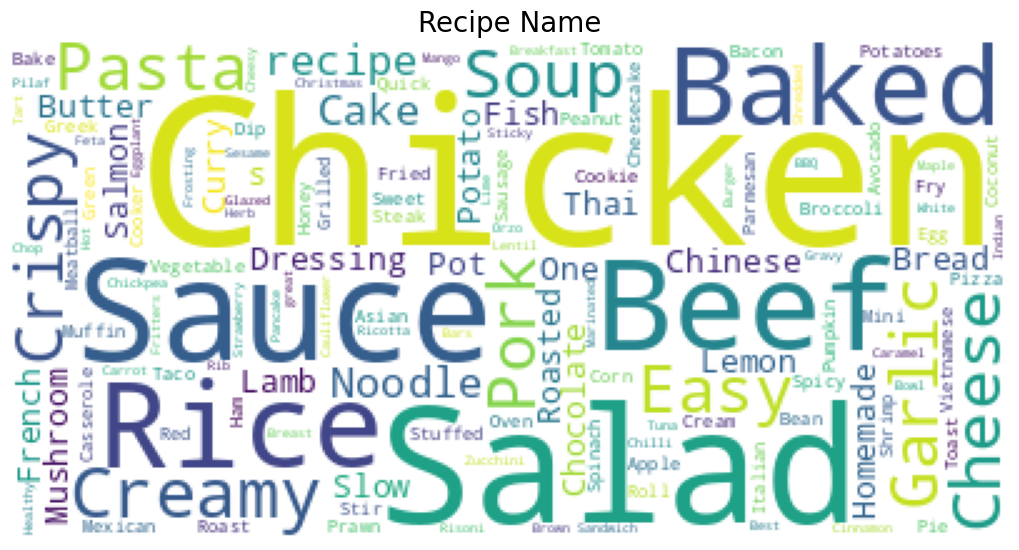

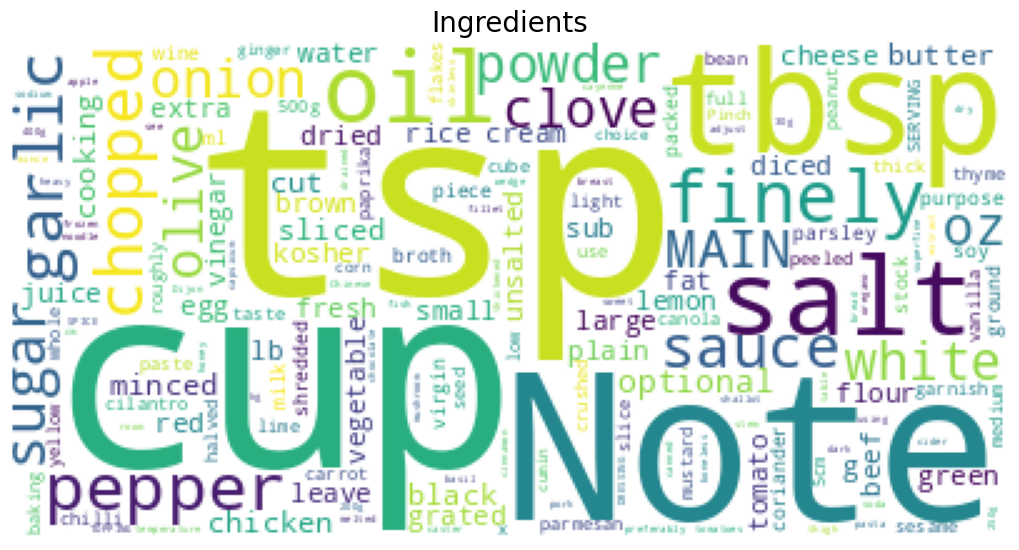

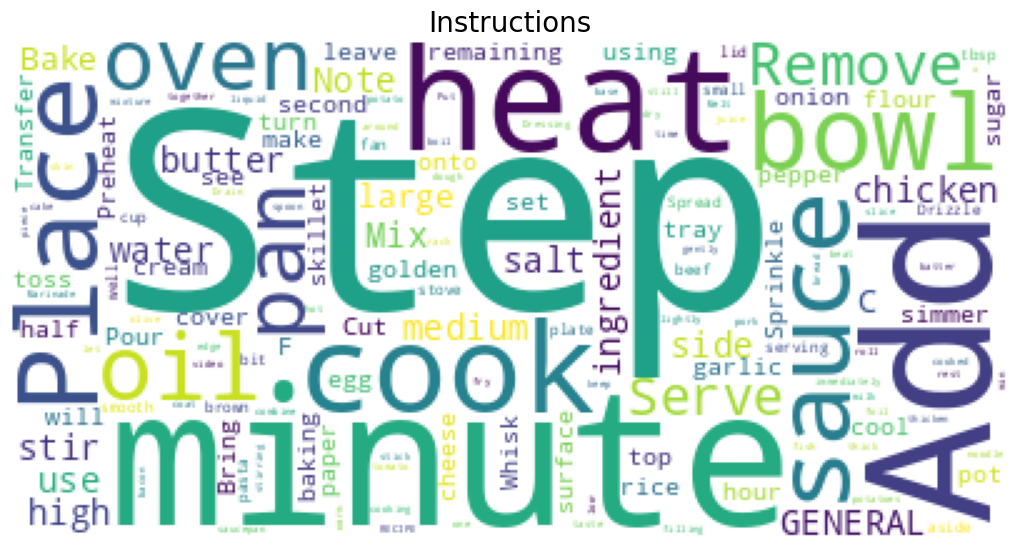

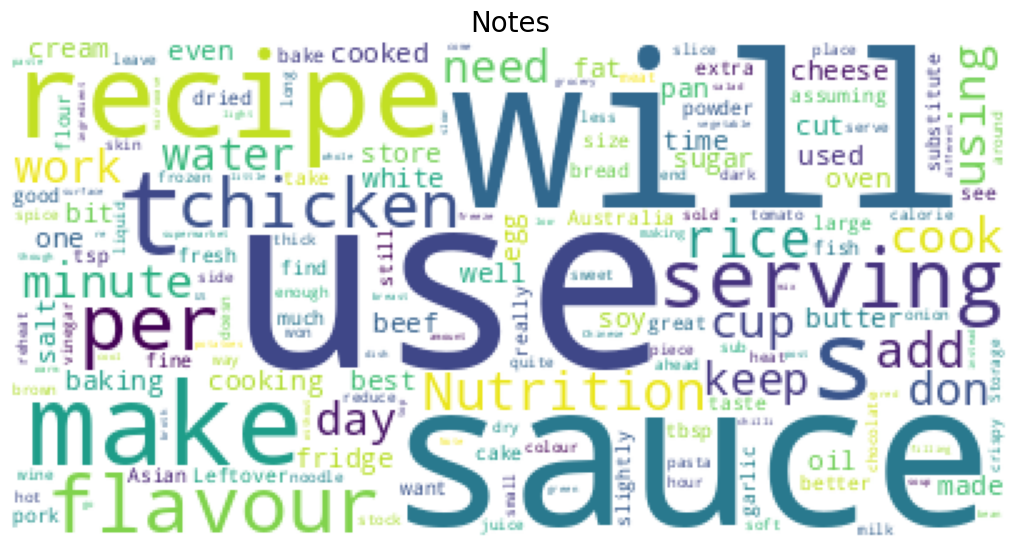

In [9]:
# Select text columns
text_columns = df.select_dtypes(include=['object']).columns.tolist()

for col in text_columns:
    # Combine all text
    text = ' '.join(df[col].dropna().astype(str))

    # Create the word cloud
    wordcloud = WordCloud(
        background_color="white",
        max_words=1000,
        collocations=False,
    ).generate(text)
    
    # Plot the word cloud
    plt.figure(figsize=(10, 10))
    plt.title(col, fontsize=20)
    plt.imshow(wordcloud)
    plt.axis("off")
    plt.tight_layout(pad=0)
    plt.show()

In [19]:
# first play around with models, get a better idea.
from transformers import AutoModelForCausalLM, AutoTokenizer

model = AutoModelForCausalLM.from_pretrained("gpt2")
tokenizer = AutoTokenizer.from_pretrained("gpt2")

prompt = "Ingredients: 2 cups flour, 1 cup sugar\nSteps:"

inputs = tokenizer(prompt, return_tensors="pt")
output_ids = model.generate(**inputs, max_new_tokens=50)

output_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)

print(output_text)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 9504.92it/s]
[transformers] Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


Ingredients: 2 cups flour, 1 cup sugar
Steps: In a large bowl, combine the flour, sugar, and flour mixture. Add the flour mixture to the dry ingredients and mix well. Add the flour mixture to the wet ingredients and mix well. Add the flour mixture to the dry ingredients and mix well


In [20]:
model = AutoModelForCausalLM.from_pretrained("gpt2")
tokenizer = AutoTokenizer.from_pretrained("gpt2")

ingredients = df.loc[0, "Ingredients"]
instructions = df.loc[0, "Instructions"]

prompt = f"{ingredients}, {instructions}"

inputs = tokenizer(prompt, return_tensors="pt")
output_ids = model.generate(**inputs, max_new_tokens=50)

output_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)

print(output_text)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 8090.99it/s]
[transformers] Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


--- MAIN ---
1 | soft bread roll (, wholemeal or white (or sliced bread, wraps))
1 | small carrot (, peeled, grated using a box grater (3/4 cup lightly packed per sandwich))
1/2 | ripe avocado
1 lightly packed cup | baby spinach leaves ((or rocket, or sliced iceberg, kale, cos/romaine, or other perky leafy greens))
1/4 cup | alfafa (, tightly packed)
1/2 | tomato (, sliced into rounds (3 – 4 slices))
3 – 4 | beetroot slices ((canned))
Few pinches | salt and pepper
--- DRESSING: ---
1/4 tsp | dijon mustard ((mainly for thickening, so it clings))
1 1/2 tsp | apple cider vinegar (, or red wine/white wine vinegar)
1 tbsp | extra virgin olive oil
1/2 | small garlic clove (, finely grated or use garlic crusher)
1/8 tsp | each salt and pepper, --- GENERAL ---
Step 01: Dress carrot first – Whisk the Dressing ingredients in a small bowl. Pour 3/4 of the dressing in a separate bowl, add the carrot, toss with fingers. (Leave remaining dressing in the other bowl for now, there shouldn't be much).


In [21]:
model = AutoModelForCausalLM.from_pretrained("gpt2")
tokenizer = AutoTokenizer.from_pretrained("gpt2")

ingredients = df.loc[0, "Ingredients"]
instructions = df.loc[0, "Instructions"]

prompt = f"Ingredients: {ingredients}\nSteps: {instructions}"

inputs = tokenizer(prompt, return_tensors="pt")
output_ids = model.generate(**inputs, max_new_tokens=50)

output_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)

print(output_text)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 11401.33it/s]
[transformers] Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


Ingredients: --- MAIN ---
1 | soft bread roll (, wholemeal or white (or sliced bread, wraps))
1 | small carrot (, peeled, grated using a box grater (3/4 cup lightly packed per sandwich))
1/2 | ripe avocado
1 lightly packed cup | baby spinach leaves ((or rocket, or sliced iceberg, kale, cos/romaine, or other perky leafy greens))
1/4 cup | alfafa (, tightly packed)
1/2 | tomato (, sliced into rounds (3 – 4 slices))
3 – 4 | beetroot slices ((canned))
Few pinches | salt and pepper
--- DRESSING: ---
1/4 tsp | dijon mustard ((mainly for thickening, so it clings))
1 1/2 tsp | apple cider vinegar (, or red wine/white wine vinegar)
1 tbsp | extra virgin olive oil
1/2 | small garlic clove (, finely grated or use garlic crusher)
1/8 tsp | each salt and pepper
Steps: --- GENERAL ---
Step 01: Dress carrot first – Whisk the Dressing ingredients in a small bowl. Pour 3/4 of the dressing in a separate bowl, add the carrot, toss with fingers. (Leave remaining dressing in the other bowl for now, there s

NER could be useful here, there is a lot of "fluff" in text. Having a structured dataset would make it easier to extract the relevant information.

In [33]:
""" Let's take a look at what different BERT options there are. Try to see what they are capturing."""

from transformers import AutoTokenizer, AutoModel
import torch
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Load the RecipeBERT model
model_name = "alexdseo/RecipeBERT"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)

def get_embedding(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True)
    with torch.no_grad():
        outputs = model(**inputs)
    # Use mean pooling to get a single vector for the text
    return outputs.last_hidden_state.mean(dim=1).squeeze().numpy()

# Prompt and candidate ingredients
query = "garlic"
candidates = ["onion", "chocolate", "basil", "vanilla", "shallot", "coffee",
              "umami", "spicy", "hot", "sour", "sweet", "salty",]

# Encode everything
query_emb = get_embedding(query)
candidate_embs = [get_embedding(c) for c in candidates]

# Calculate similarities
similarities = cosine_similarity([query_emb], candidate_embs)[0]

# Results
for score, word in sorted(zip(similarities, candidates), reverse=True):
    print(f"{word}: {score:.4f}")

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 8334.71it/s]
[transformers] BertModel LOAD REPORT from: alexdseo/RecipeBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


onion: 0.9444
sour: 0.8978
spicy: 0.8920
vanilla: 0.8891
chocolate: 0.8880
basil: 0.8877
coffee: 0.8761
sweet: 0.8469
hot: 0.8038
shallot: 0.7708
salty: 0.7521
umami: 0.6451


RecipeBERT stores garlic and chocolate very close together?

In [8]:
from recifine.inferencing.inference import ReciFineNER
import pandas as pd

ner = ReciFineNER.from_pretrained(
    model="recipebert",
    task_formulation="traditional",
)

df = pd.read_csv("recipes.csv")

ingredients = df.loc[0, "Ingredients"]
instructions = df.loc[0, "Instructions"]

text = f"{ingredients}, {instructions}"

#text = "Add 2 cups of chopped onions and fry until golden ."

prediction = ner.process_text(
    text
)

print(prediction)

100%|██████████| 1/1 [00:00<00:00, 161.82it/s]
INFO:recifine.inferencing.inference:***** Running inference *****
Inferencing: 100%|##########| 1/1 [00:00<00:00,  4.50it/s]

[{'answer': {'FOOD STATE': ['soft', 'wholemeal', 'white', 'sliced', 'small', 'peeled,', 'grated', 'lightly packed', 'ripe', 'lightly packed', 'baby', 'sliced', 'perky', 'tightly packed)\n1/2', 'sliced', 'rounds', 'slices))\n3', 'slices', 'virgin', 'small', 'finely grated'], 'FOOD': ['bread roll', 'bread,', 'carrot', 'avocado\n1', 'spinach leaves', 'rocket,', 'iceberg,', 'kale,', 'cos/romaine,', 'leafy greens))\n1/4', 'alfafa (,', 'tomato', 'beetroot', 'salt', 'pepper\n--- DRESSING:', 'dijon mustard', 'apple cider vinegar', 'red wine/white wine vinegar)\n1', 'olive oil\n1/2', 'garlic clove', 'garlic crusher)\n1/8', 'salt', 'pepper,', 'Dress', 'carrot', 'Dressing ingredients'], 'ACTION BY CHEF': ['wraps))\n1', 'Whisk'], 'TOOL': ['box grater', 'sandwich))\n1/2', 'cup'], 'ACTION BY FOOD': ['thickening,', 'clings))\n1'], 'QUANTITY': ['extra', 'each']}, 'words_list': ['---', 'MAIN', '---\n1', '|', 'soft', 'bread', 'roll', '(,', 'wholemeal', 'or', 'white', '(or', 'sliced', 'bread,', 'wraps))\